# Entrenamiento YOLOv8 — Arroz IA v2
**Clases:** `Brown_Spot` (0) | `Leaf_Blight` (1) | `healthy` (2)  
**Split:** 70 / 20 / 10 — 2722 imágenes totales  
**Modelo base:** YOLOv8n

## 1. Verificar GPU

In [ ]:
!nvidia-smi
import torch
print(f"\nCUDA disponible : {torch.cuda.is_available()}")
print(f"GPU             : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'No GPU'}")

Tue May 26 22:51:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   55C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Montar Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
print("Drive montado correctamente.")

Mounted at /content/drive
Drive montado correctamente.


## 3. Descomprimir dataset
> El archivo `dataset-v2.zip` ya tiene el split 70/20/10 y los labels normalizados. No requiere preprocesamiento.

In [ ]:
import os, zipfile, shutil

ZIP_PATH = '/content/drive/MyDrive/2026/upeu-2026-1/Investigacion 4/dataset-entrenamiento/dataset-v2.zip'
DATASET_DIR = '/content/dataset-v2'

if os.path.exists(DATASET_DIR):
    shutil.rmtree(DATASET_DIR)
    print("Directorio previo eliminado.")

print(f"Descomprimiendo {ZIP_PATH} ...")
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(DATASET_DIR)
print("Descompresión completada.\n")

for split in ['train', 'valid', 'test']:
    imgs = len(os.listdir(f'{DATASET_DIR}/{split}/images'))
    lbls = len(os.listdir(f'{DATASET_DIR}/{split}/labels'))
    print(f"  {split:6s}: {imgs} imgs | {lbls} labels")

Descomprimiendo /content/drive/MyDrive/2026/upeu-2026-1/Investigacion 4/dataset-entrenamiento/dataset-v2.zip ...
Descompresión completada.

  train : 1904 imgs | 1904 labels
  valid : 545 imgs | 545 labels
  test  : 273 imgs | 273 labels


## 4. Instalar Ultralytics

In [ ]:
!pip install ultralytics -q
import ultralytics
ultralytics.checks()

Ultralytics 8.4.55 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 48.2/112.6 GB disk)


## 5. Entrenar YOLOv8n

| Parámetro | Valor | Notas |
|-----------|-------|-------|
| `MODEL`   | `yolov8n.pt` | nano — rápido, cambia a `yolov8s.pt` para más precisión |
| `EPOCHS`  | 100 | Early stopping en 20 épocas sin mejora |
| `IMGSZ`   | 640 | Resolución estándar YOLOv8 |
| `BATCH`   | 16 | Reducir a 8 si hay OOM |
| `PROJECT` | Drive/yolov8_runs | Los pesos se guardan en Drive |

In [ ]:
from ultralytics import YOLO

MODEL    = 'yolov8n.pt'
DATA     = f'{DATASET_DIR}/data.yaml'
EPOCHS   = 100
IMGSZ    = 640
BATCH    = 16
PATIENCE = 20
PROJECT  = '/content/drive/MyDrive/yolov8_runs'
NAME     = 'arroz_v2'

model = YOLO(MODEL)

results = model.train(
    data     = DATA,
    epochs   = EPOCHS,
    imgsz    = IMGSZ,
    batch    = BATCH,
    patience = PATIENCE,
    project  = PROJECT,
    name     = NAME,
    device   = 0,
    workers  = 2,
    exist_ok = True,
    plots    = True,
    save     = True,
)

print(f"\nEntrenamiento finalizado.")
print(f"Resultados guardados en: {PROJECT}/{NAME}")

Ultralytics 8.4.55 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset-v2/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=arroz_v2, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=20, 

## 6. Ver curvas de entrenamiento

--- results.png ---


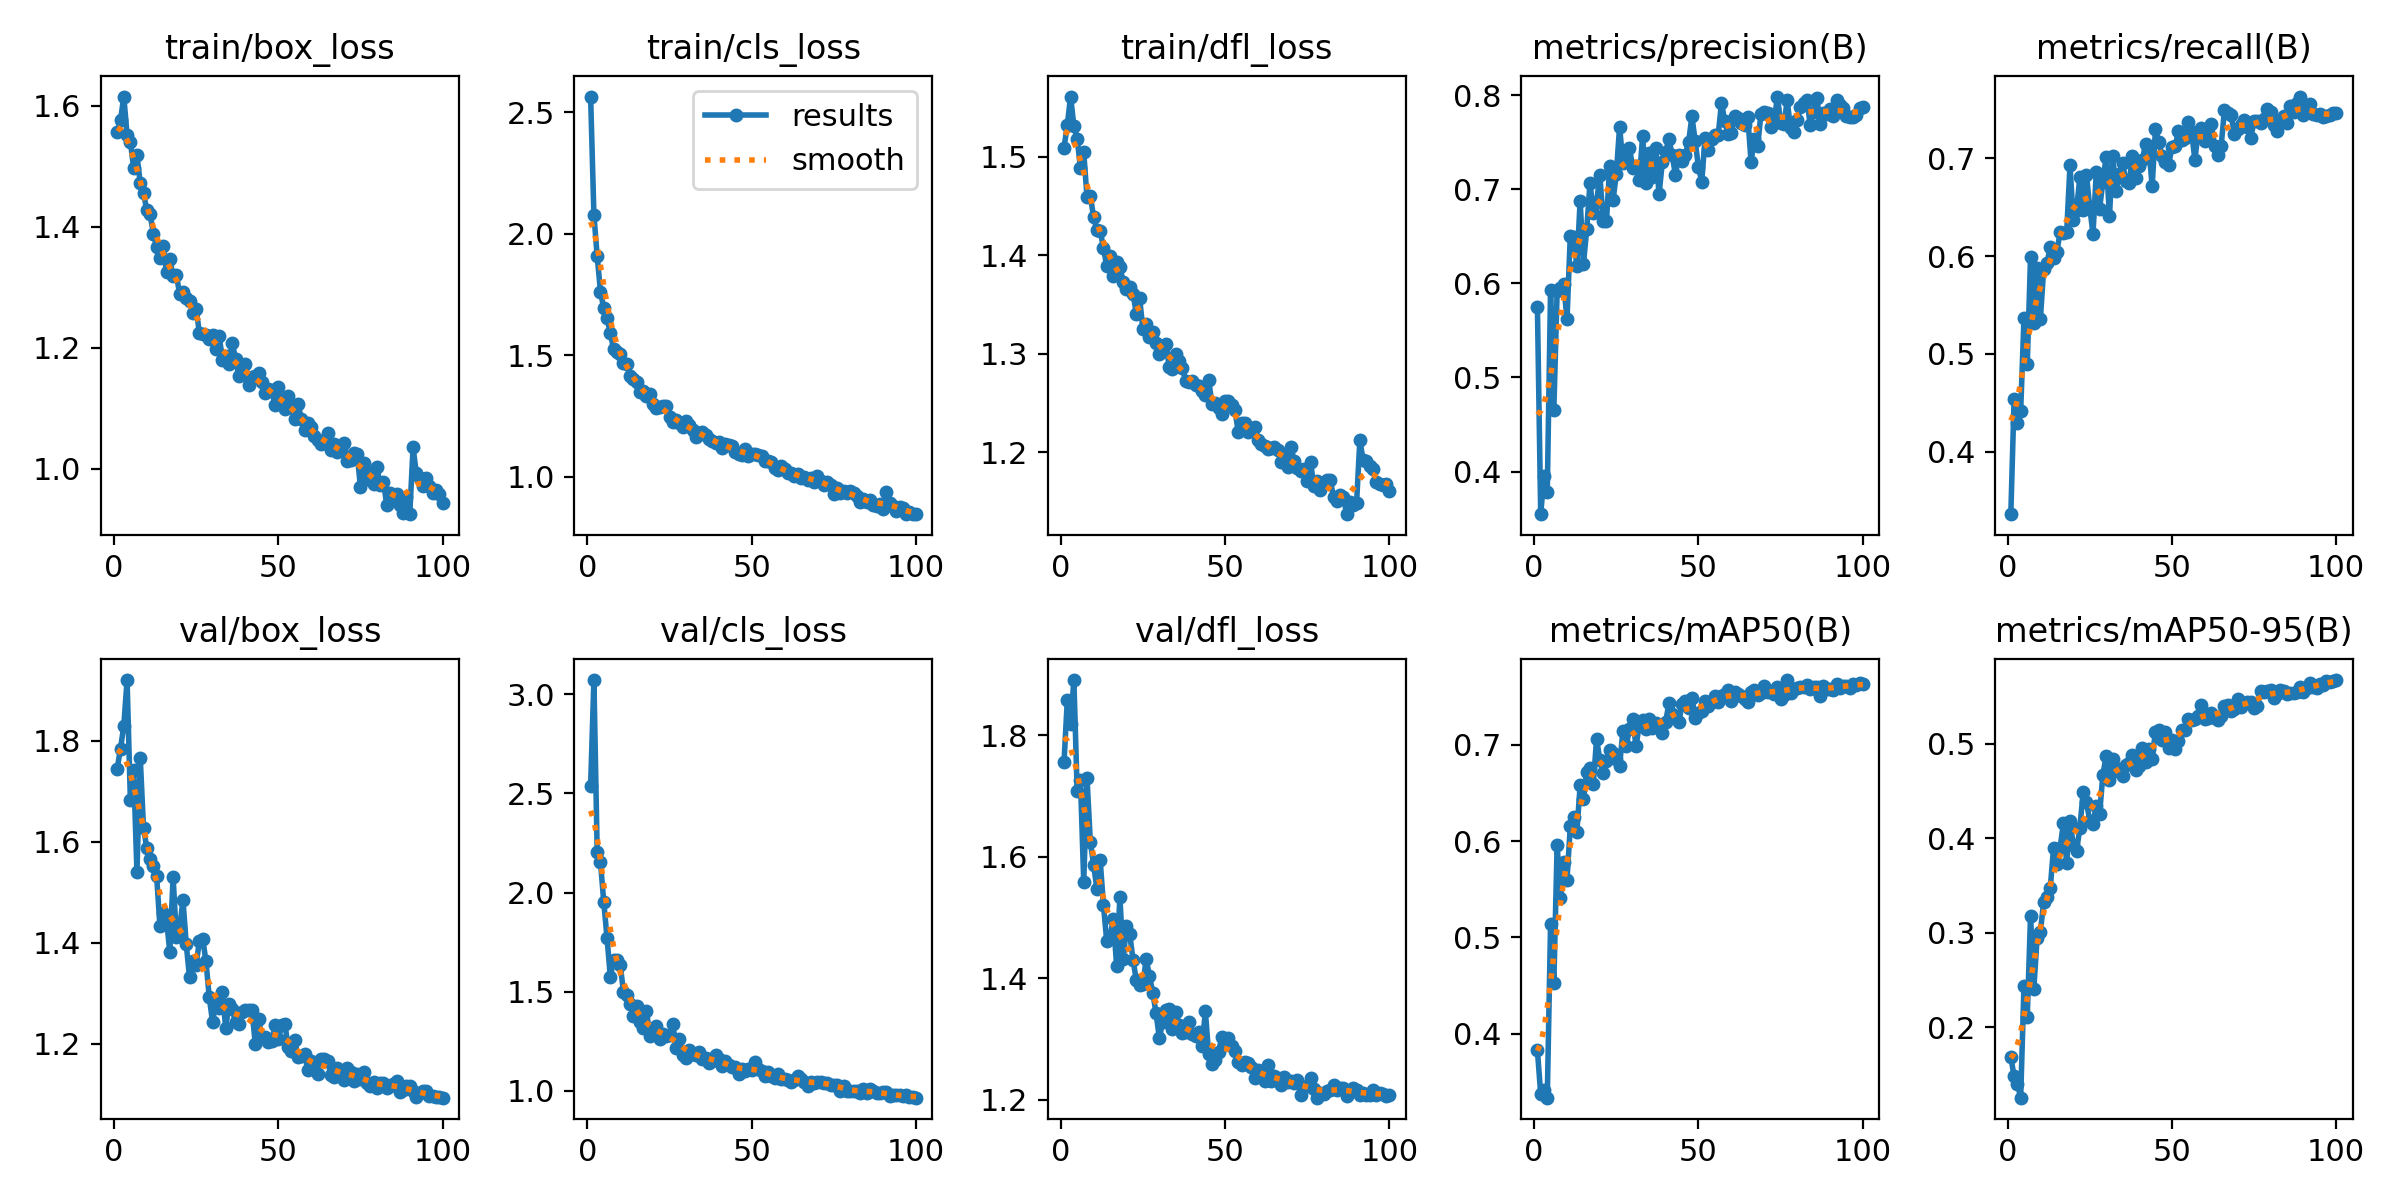

--- confusion_matrix_normalized.png ---


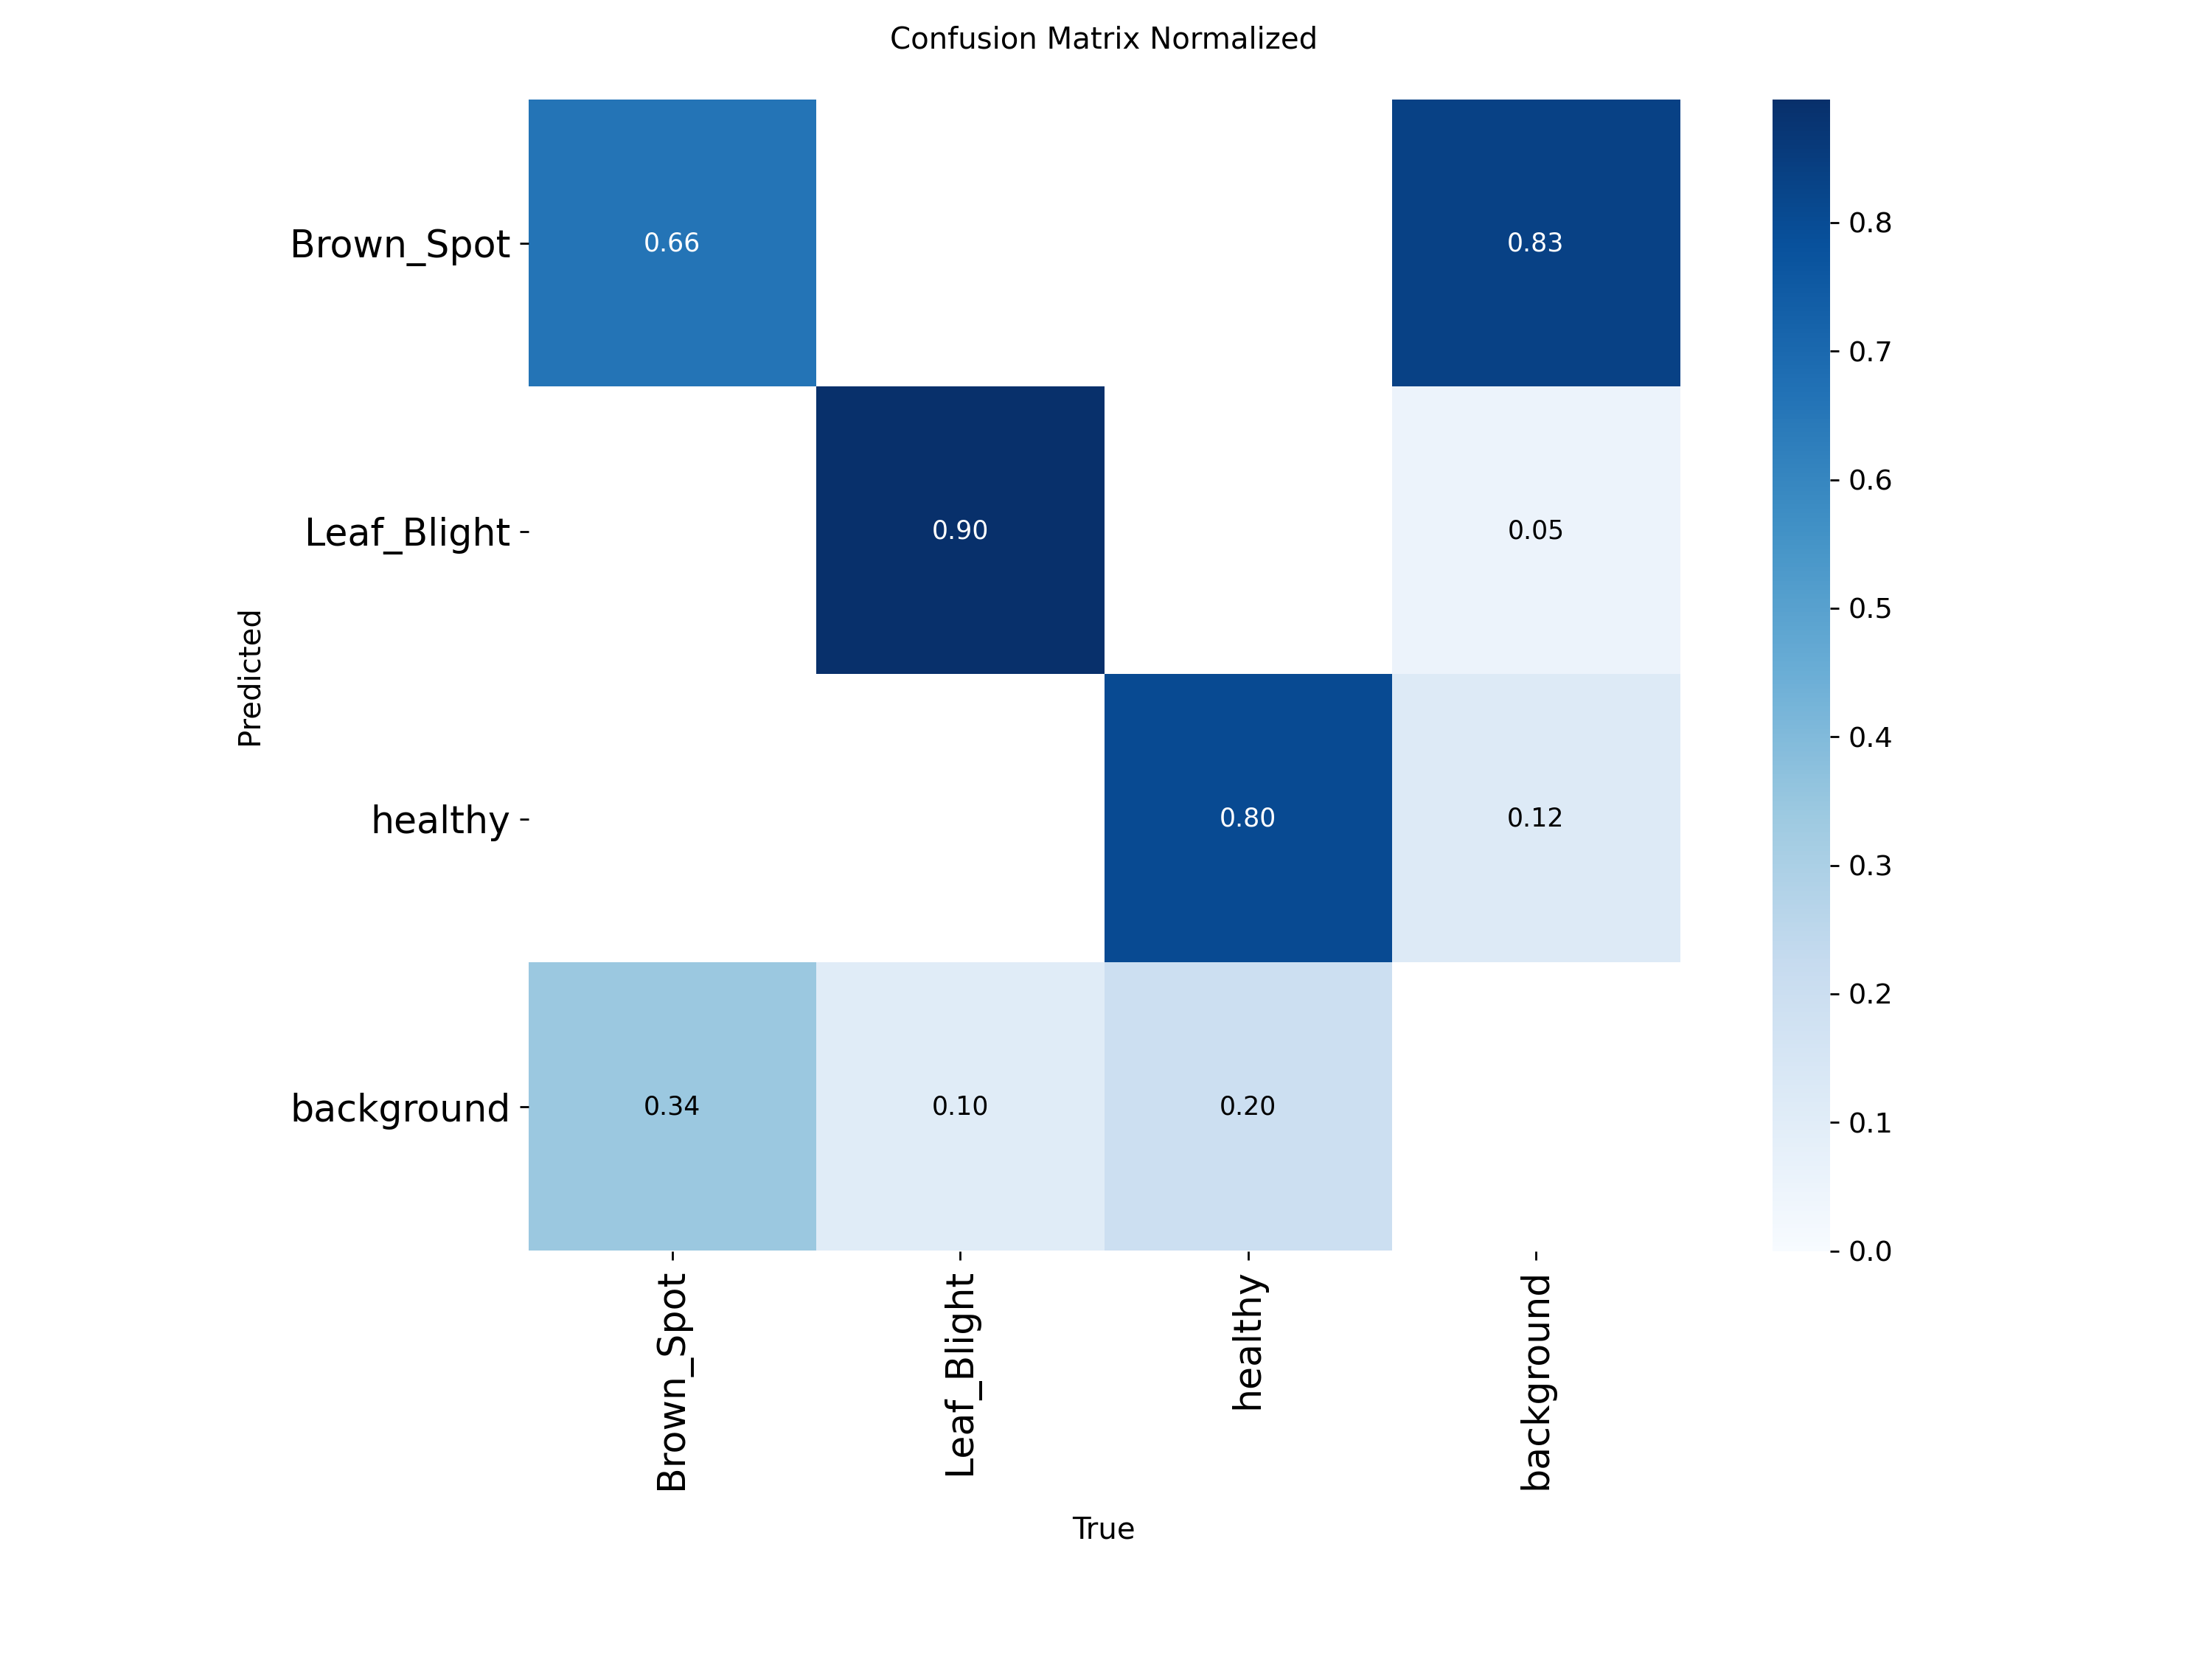

In [ ]:
from IPython.display import Image, display
import glob

run_dir = f'{PROJECT}/{NAME}'

for img_name in ['results.png', 'confusion_matrix_normalized.png',
                 'PR_curve.png', 'F1_curve.png']:
    matches = glob.glob(f'{run_dir}/{img_name}')
    if matches:
        print(f'--- {img_name} ---')
        display(Image(matches[0], width=900))

## 7. Validar en el set de test

In [ ]:
best_pt    = f'{PROJECT}/{NAME}/weights/best.pt'
model_best = YOLO(best_pt)

metrics = model_best.val(
    data   = DATA,
    split  = 'test',
    imgsz  = IMGSZ,
    device = 0,
)

class_names = ['Brown_Spot', 'Leaf_Blight', 'healthy']

print('\n=== MÉTRICAS EN TEST ===')
print(f'mAP@0.5      : {metrics.box.map50:.4f}')
print(f'mAP@0.5:0.95 : {metrics.box.map:.4f}')
print(f'Precision    : {metrics.box.mp:.4f}')
print(f'Recall       : {metrics.box.mr:.4f}')
print('\n--- AP50 por clase ---')
for i, ap in enumerate(metrics.box.ap50):
    print(f'  {class_names[i]:12s}: {ap:.4f}')

Ultralytics 8.4.55 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,006,233 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 15.1±14.7 MB/s, size: 136.6 KB)
val: Scanning /content/dataset-v2/test/labels... 273 images, 5 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 273/273 431.1it/s 0.6s
val: /content/dataset-v2/test/images/Healthy_rice_leaf (25)_jpg.rf.N8JbEMEn7o4n8vphA1bm.jpg: corrupt JPEG restored and saved
val: /content/dataset-v2/test/images/Healthy_rice_leaf (35)_jpg.rf.i5HQOZJyG4sKHbDz6W9j.jpg: corrupt JPEG restored and saved
val: /content/dataset-v2/test/images/Healthy_rice_leaf (38)_jpg.rf.2tD6tlNNBKXuSpwsgC91.jpg: corrupt JPEG restored and saved
val: /content/dataset-v2/test/images/Healthy_rice_leaf (47)_jpg.rf.Cj2m7sgxrXgbzqf0NYJW.jpg: corrupt JPEG restored and saved
val: New cache created: /content/dataset-v2/test/labels.cache
                 Class     Images  Instances      Box(P          

## 8. Exportar modelo ONNX
> El output del nuevo modelo es `[1, 7, 8400]` (4 bbox + 3 clases).  
> Actualizar `RiceClassifier.kt`: fila 4 = Brown_Spot · fila 5 = Leaf_Blight · fila 6 = healthy

In [ ]:
model_best.export(format='onnx', imgsz=IMGSZ, simplify=True)
print(f'Modelo ONNX exportado en: {PROJECT}/{NAME}/weights/')
print('Output shape: [1, 7, 8400]')
print('  fila 4 → Brown_Spot  (clase 0)')
print('  fila 5 → Leaf_Blight (clase 1)')
print('  fila 6 → healthy     (clase 2)')

Ultralytics 8.4.55 🚀 Python-3.12.13 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino/

PyTorch: starting from '/content/drive/MyDrive/yolov8_runs/arroz_v2/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (5.9 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxslim>=0.1.71', 'onnxruntime'] not found, attempting AutoUpdate...
Using Python 3.12.13 environment at: /usr
Resolved 12 packages in 224ms
Prepared 4 packages in 1.47s
Installed 4 packages in 281ms
 + colorama==0.4.6
 + onnx==1.21.0
 + onnxruntime==1.26.0
 + onnxslim==0.1.94

requirements: AutoUpdate success ✅ 2.6s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.21.0 opset 20...
ONNX: slimming with onnxslim 0.1.94...
ONNX: export success ✅ 4.2s, saved as '/cont

## 9. Inferencia de prueba sobre imágenes del set test


0: 640x640 1 healthy, 10.5ms
1: 640x640 1 Leaf_Blight, 10.5ms
2: 640x640 1 Leaf_Blight, 10.5ms
3: 640x640 1 Leaf_Blight, 10.5ms
4: 640x640 3 Brown_Spots, 10.5ms
5: 640x640 1 Leaf_Blight, 10.5ms
Speed: 4.0ms preprocess, 10.5ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/inference/test_v2
Inferencia sobre 6 imágenes:


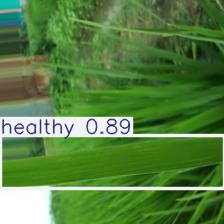

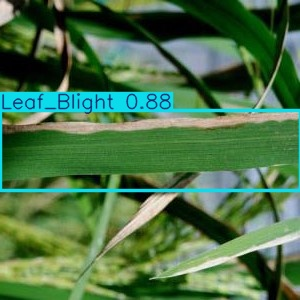

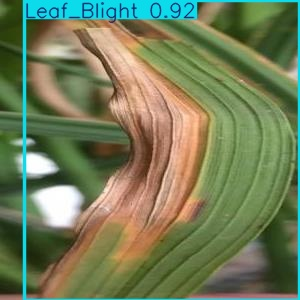

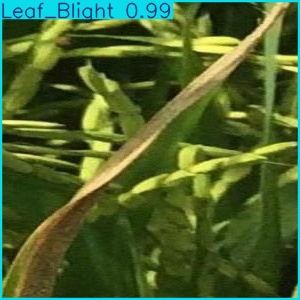

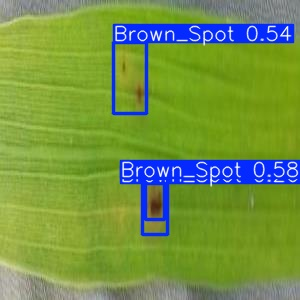

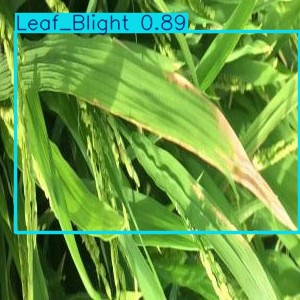

In [ ]:
from pathlib import Path
from IPython.display import Image as IPImage

test_images = glob.glob(f'{DATASET_DIR}/test/images/*')[:6]

if not test_images:
    print("No se encontraron imágenes de test.")
else:
    results_inf = model_best.predict(
        source   = test_images,
        imgsz    = IMGSZ,
        conf     = 0.25,
        save     = True,
        project  = '/content/inference',
        name     = 'test_v2',
        exist_ok = True,
    )
    print(f"Inferencia sobre {len(results_inf)} imágenes:")
    for r in results_inf:
        img_path = Path(r.save_dir) / Path(r.path).name
        if img_path.exists():
            display(IPImage(filename=str(img_path), width=700))